# 13 — Image uncertainty with current shared checkpoints

This notebook asks whether repeated-prediction variation helps identify images
for review **beyond the model's ordinary prediction score**. It loads an existing
checkpoint and performs inference only. The default is the weak-augmentation,
unchanged-preprocessing B0 control, using its recorded best epoch, not epoch 12.

These are **inner-validation diagnostics**. The same patients helped select the
checkpoint epoch and pilot recipes, so these results are exploratory. They are
neither full out-of-fold (OOF) results nor reserved-test performance. A pilot AP
leader does not become the final architecture here.

The original three-epoch, outer-fold-0 experiment and its executed outputs are
preserved in `../archive/image_uncertainty_three_epoch_fold0.ipynb`.
Its existing result files remain unchanged. Every current execution creates a
new directory under `results/image_uncertainty_runs/`.


## 1. Choose the checkpoint explicitly

The shared loader reconstructs the trained model and exact deterministic
preparation. We check the run, recipe, selected best epoch, checkpoint hash,
recorded fitting/validation memberships and original prediction export.

The defaults below are the experimental B0 control. To inspect another supported
checkpoint, explicitly set `SOURCE_RUN`, `ARCHITECTURE` and `RECIPE_ID` together:
for example `architecture_pilot_3h_v1`, `densenet121`, `low_none`, or
`architecture_pilot_3h_v1`, `convnext_tiny`, `high_sqrt`. This is an explicit
diagnostic choice, not automatic architecture selection. `CONDITION_ID` applies
to a controlled B0 condition only. Missing or incompatible inputs raise an error.


In [1]:
import json
import sys
from datetime import datetime, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from IPython.display import display, Markdown

PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "src/melanoma_detection").is_dir() and (path / "configs/image_model.yaml").is_file())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from melanoma_detection.image_uncertainty import (
    load_selected_checkpoint, run_smoke, run_inference, tta_transform,
    snapshot_preserved_artifacts, assert_preserved_artifacts,
)
from melanoma_detection.image_uncertainty_evaluation import (
    validate_raw, aggregate_raw, convergence_summary,
    evaluate_referral, referral_patient_bootstrap,
)
from melanoma_detection.image_model import file_sha256, transformation_profile, make_transform
from melanoma_detection.metadata_evaluation import probability_metrics, calibration_bins

SOURCE_RUN = "b0_augmentation_12e_v1"
ARCHITECTURE = "efficientnet_b0"
RECIPE_ID = "lr3e5_sqrt"
CONDITION_ID = "A"
MC_PASSES = 30
INFERENCE_SEED = 20261004
REFERRAL_SEED = 17042
BOOTSTRAP_SEED = 20242
REFERRAL_FRACTIONS = (0.0, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50)
RANDOM_REPEATS = 100
PATIENT_BOOTSTRAPS = 2000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUTPUT_DIR = PROJECT_ROOT / "results/image_uncertainty_runs" / f"{ARCHITECTURE}_{RECIPE_ID}_mc30_tta4_{stamp}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
(OUTPUT_DIR / "figures").mkdir()
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "figure.facecolor": "white", "axes.facecolor": "white"})
COLORS = {"uncertainty_sd": "#245D8C", "prediction_score": "#B46A20",
    "predictive_entropy": "#747133", "random": "#666666"}
LINESTYLES = {"uncertainty_sd": "-", "prediction_score": "--",
    "predictive_entropy": "-.", "random": ":"}
def save_json(name, value):
    (OUTPUT_DIR / name).write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
def save_figure(name, figure):
    figure.savefig(OUTPUT_DIR / "figures" / name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(figure)
print("Source:", SOURCE_RUN, "| architecture:", ARCHITECTURE, "| recipe:", RECIPE_ID)
print("Device:", DEVICE, "| outputs:", OUTPUT_DIR)


Source: b0_augmentation_12e_v1 | architecture: efficientnet_b0 | recipe: lr3e5_sqrt
Device: cuda | outputs: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\results\image_uncertainty_runs\efficientnet_b0_lr3e5_sqrt_mc30_tta4_20261003T235530258956Z


## 2. Recover the exact evaluation patients

We use the saved first inner-validation fold inside outer-training folds 1–4.
The outer fold 0 patients remain excluded. Patient IDs define separation; they
are not model inputs. The adapter verifies the ordered frame identities against
the checkpoint and validates source-image hashes before prediction. It never
loads a reserved-test table or predicts the excluded outer fold.

The weak B0 control has 3,660 fitting images / 225 patients and 1,834 validation
images / 113 patients, including 33 malignant images. Membership is reconstructed
from recorded artifacts, not recreated by a newly sampled split.


In [2]:
archive_path = PROJECT_ROOT / "notebooks/archive/image_uncertainty_three_epoch_fold0.ipynb"
protected = snapshot_preserved_artifacts(PROJECT_ROOT, archive_path=archive_path)
context = load_selected_checkpoint(PROJECT_ROOT, SOURCE_RUN, RECIPE_ID,
    architecture=ARCHITECTURE, condition_id=CONDITION_ID, device=DEVICE)
frame = context["frame"].assign(image_id=context["frame"].image_name)
save_json("checkpoint_and_split_provenance.json", context["provenance"])
display(pd.DataFrame([
    {"partition": name, "images": len(rows), "patients": rows.patient_id.nunique(),
     "malignant_images": int(rows.target.sum()) if name != "outer_excluded" else None}
    for name, rows in [("fitting", context["fitting_frame"]),
                       ("inner_validation", frame), ("outer_excluded", context["excluded_frame"])]
]))
print("Selected epoch:", context["checkpoint"]["epoch"], "| trained dropout:", context["spec"]["dropout"])
print("Deterministic preparation:", make_transform(context["spec"], training=False))


,partition,images,patients,malignant_images
0,fitting,3660,225,70.0
1,inner_validation,1834,113,33.0
2,outer_excluded,1370,84,NaN


Selected epoch: 6 | trained dropout: 0.2
Deterministic preparation: Compose(
    Compose(
    Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
)
)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 3. Run a small smoke check first

Before full inference, a small sample checks the loader, deterministic repeat
predictions and agreement with the recorded prediction export. Two seeded MC
passes must activate only explicit dropout, vary with different seeds and repeat
with the same seed. BatchNorm buffers and all model state must remain unchanged.
Identity TTA must reproduce the deterministic scores. Any failed check stops
execution before the 30-pass run.


In [3]:
smoke = run_smoke(context, n_images=16, seed=INFERENCE_SEED)
save_json("smoke_receipt.json", smoke)
display(pd.DataFrame(list(smoke.items()), columns=["Smoke check", "Result"]))
print("Smoke check passed; full inner-validation inference is now permitted.")


,Smoke check,Result
0,passed,True
1,images,16
2,malignant_images,2
3,saved_comparison_original_batch_images,192
4,saved_comparison_original_microbatch,64
5,seed,20261004
6,preprocessing_repeatable,True
7,deterministic_repeatable,True
8,identity_tta_agreement,True
9,saved_prediction_max_abs_difference,0.0


Smoke check passed; full inner-validation inference is now permitted.


### Inspect the conservative views

These examples show the exact prepared image and the three flips. One benign
and one malignant example illustrate framing; labels do not choose transform
parameters. The operation rearranges existing pixels without deleting pixels
or generating border fragments. No transform is selected by diagnostic results.


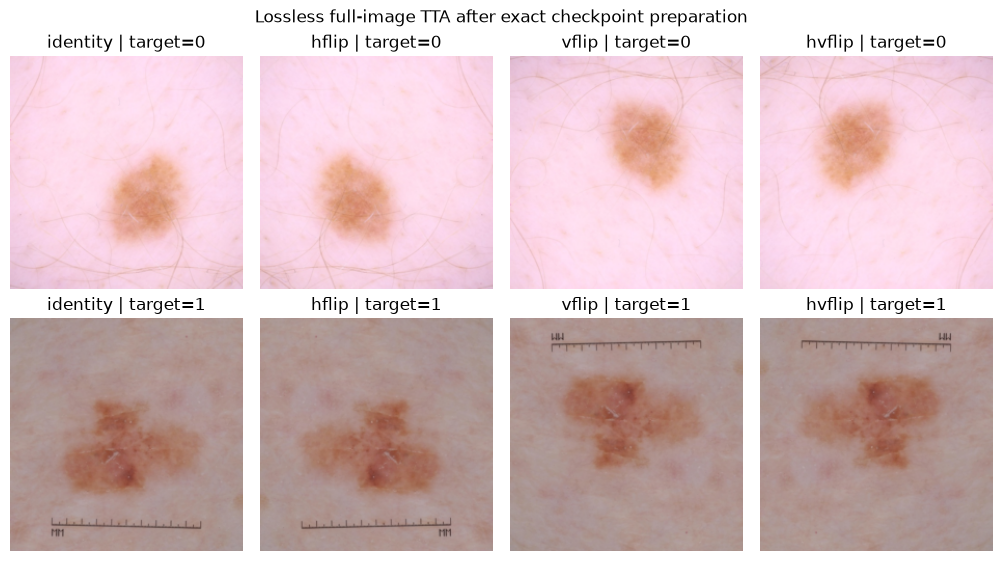

In [4]:
examples = pd.concat([frame[frame.target == 0].head(1), frame[frame.target == 1].head(1)])
prepare = make_transform(context["spec"], training=False)
mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
fig, axes = plt.subplots(len(examples), 4, figsize=(10, 5.5), constrained_layout=True, squeeze=False)
for row_index, row in enumerate(examples.itertuples()):
    with Image.open(row.image_path) as source:
        prepared = prepare(source.convert("RGB"))
    for col, view in enumerate(["identity", "hflip", "vflip", "hvflip"]):
        pixels = (tta_transform(prepared, view) * std + mean).permute(1, 2, 0).numpy()
        axes[row_index, col].imshow(np.clip(pixels, 0, 1))
        axes[row_index, col].set_title(f"{view} | target={row.target}")
        axes[row_index, col].axis("off")
fig.suptitle("Lossless full-image TTA after exact checkpoint preparation")
save_figure("conservative_tta_examples.png", fig)


## 4. Keep two sources of variation separate

**MC dropout** predicts the same deterministically prepared image 30 times.
Only explicit dropout layers become active; the trained rate remains unchanged
(0.2 for these checkpoints). BatchNorm and native stochastic depth stay in
evaluation mode. Each pass has a recorded seed. The mean is an ensemble
**prediction score**; the sample standard deviation (SD, denominator 29) measures
sensitivity to these dropout masks. It does not measure all possible uncertainty.

**TTA** keeps the whole model in evaluation mode. Four equally weighted views
are identity, horizontal flip, vertical flip and both flips. They act on the
exact deterministically prepared tensor, after whole-image resize and any
recorded preprocessing. No crop, padding, arbitrary rotation or colour change is
introduced. Spatial flips preserve every pixel and commute with normalisation.
TTA SD (sample denominator 3) measures sensitivity across these particular views;
it is not a Monte Carlo estimate of an underlying population and cannot be
compared numerically with dropout SD as total uncertainty.

All scores are sigmoid outputs in [0,1]. They are **not calibrated probabilities**.
Training loss weighting can change the score scale. No calibrator or decision
threshold is fitted here.


In [5]:
inference = run_inference(context, mc_passes=MC_PASSES, seed=INFERENCE_SEED,
    batch_size=context["training"]["microbatch"], progress=lambda message: print(message, flush=True))
mc_raw, tta_raw = inference["mc_raw"], inference["tta_raw"]
mc_pass_ids = list(range(1, MC_PASSES + 1))
tta_pass_ids = ["identity", "hflip", "vflip", "hvflip"]
validate_raw(mc_raw, frame, mc_pass_ids)
validate_raw(tta_raw, frame, tta_pass_ids)
save_json("raw_prediction_checks.json", {
    "all_raw_scores_finite_in_unit_interval": True,
    "unique_image_pass_keys": True, "exact_image_and_pass_coverage": True,
    "patient_and_target_metadata_agree": True,
    "evaluation_images": len(frame), "mc_rows": len(mc_raw), "tta_rows": len(tta_raw),
    "mc_expected_pass_ids": mc_pass_ids, "tta_expected_pass_ids": tta_pass_ids,
})
mc_raw.to_csv(OUTPUT_DIR / "mc_raw_predictions.csv", index=False)
tta_raw.to_csv(OUTPUT_DIR / "tta_raw_predictions.csv", index=False)
inference["deterministic"].to_csv(OUTPUT_DIR / "deterministic_predictions.csv", index=False)
save_json("inference_checks.json", inference["checks"])
save_json("inference_provenance.json", inference["provenance"])
print("Validated raw rows:", len(mc_raw), "MC and", len(tta_raw), "TTA")


Prepared 1834 exact deterministic image tensors (1053 MiB).


MC dropout pass 1/30 complete.


MC dropout pass 2/30 complete.


MC dropout pass 3/30 complete.


MC dropout pass 4/30 complete.


...

Deterministic TTA identity complete.


Deterministic TTA hflip complete.


Deterministic TTA vflip complete.


Deterministic TTA hvflip complete.


Validated raw rows: 55020 MC and 7336 TTA


## 5. Validate before aggregation

Each raw row is one image and one pass/view. The validator rejects NaN, infinity,
scores outside [0,1], repeated image/pass keys, extra images or passes, changed
patient IDs/labels, and incomplete passes or image coverage. Only complete,
validated raw predictions enter a summary. The saved raw tables allow every
mean and SD to be independently recomputed.


In [6]:
mc_summary = aggregate_raw(mc_raw, frame, mc_pass_ids).rename(columns={
    "mean_score": "mc_mean_score", "score_sd": "mc_score_sd", "n_passes": "mc_n_passes"})
tta_summary = aggregate_raw(tta_raw, frame, tta_pass_ids).rename(columns={
    "mean_score": "tta_mean_score", "score_sd": "tta_score_sd", "n_passes": "tta_n_passes"})
summary = inference["deterministic"].merge(mc_summary,
    on=["image_id", "patient_id", "target"], validate="one_to_one").merge(tta_summary,
    on=["image_id", "patient_id", "target"], validate="one_to_one")
assert len(summary) == len(frame)
summary["split"] = "inner_validation"
summary["evaluation_status"] = "exploratory_inner_validation_not_outer_oof"
summary["source_run"] = SOURCE_RUN
summary["recipe_id"] = RECIPE_ID
summary["selected_epoch"] = context["checkpoint"]["epoch"]
summary.to_csv(OUTPUT_DIR / "prediction_summary.csv", index=False)
display(summary[["image_id", "target", "base_score", "mc_mean_score", "mc_score_sd",
                 "tta_mean_score", "tta_score_sd"]].head(8).round(5))


,image_id,target,base_score,mc_mean_score,mc_score_sd,tta_mean_score,tta_score_sd
0,ISIC_0086632,0,0.00039,0.00045,0.00028,0.00068,0.00041
1,ISIC_0091016,0,0.06605,0.06912,0.01456,0.07360,0.01204
2,ISIC_0094701,0,0.00468,0.00484,0.00142,0.00629,0.00123
3,ISIC_0113820,0,0.00164,0.00168,0.00076,0.00228,0.00082
4,ISIC_0124849,0,0.00889,0.00878,0.00248,0.01066,0.00136
5,ISIC_0134357,0,0.01210,0.01406,0.00512,0.01305,0.00176
6,ISIC_0147817,0,0.01099,0.01081,0.00257,0.01530,0.00537
7,ISIC_0160831,0,0.01118,0.01128,0.00309,0.01268,0.00495


## 6. Check whether 30 passes are stable enough

We compare the first 5, 10 and 20 seeded passes with the same full 30-pass
reference, without selecting a pass count from labels. Mean/SD absolute
differences and SD rank agreement show numerical stability, while overlap of
the highest-SD 20% shows ranking stability. The 30-pass reference is itself
finite; agreement with it is not proof of convergence to an exact expectation.


,n_passes,reference_passes,mean_score_mae,score_sd_mae,sd_spearman,top20_overlap_fraction
0,5,30,0.00347,0.00293,0.94766,0.84469
1,10,30,0.00209,0.00182,0.97961,0.91553
2,20,30,0.00102,0.00085,0.99491,0.95095


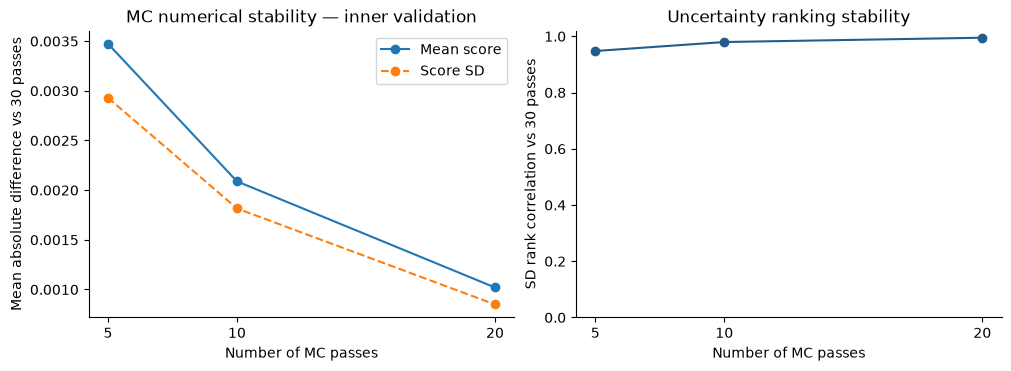

In [7]:
convergence = convergence_summary(mc_raw, frame, mc_pass_ids)
convergence.to_csv(OUTPUT_DIR / "mc_convergence.csv", index=False)
display(convergence.round(5))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for column, label, style in [("mean_score_mae", "Mean score", "-"), ("score_sd_mae", "Score SD", "--")]:
    axes[0].plot(convergence["n_passes"], convergence[column], marker="o", linestyle=style, label=label)
axes[0].set(xlabel="Number of MC passes", ylabel="Mean absolute difference vs 30 passes",
            title="MC numerical stability — inner validation")
axes[0].legend()
axes[0].set_xticks(convergence.n_passes)
axes[1].plot(convergence["n_passes"], convergence["sd_spearman"], marker="o", color="#245D8C")
axes[1].set(xlabel="Number of MC passes", ylabel="SD rank correlation vs 30 passes",
            ylim=(0, 1.02), title="Uncertainty ranking stability")
axes[1].set_xticks(convergence.n_passes)
save_figure("mc_convergence.png", fig)


## 7. Compare prediction quality and descriptive reliability

Average precision (AP) and ROC-AUC describe ranking; AP is particularly useful
with rare malignant images. Log loss and Brier score describe score-label
agreement. The fitting-prevalence constant is a reference computed without
validation labels, not a newly fitted calibrator.

The reliability diagram groups similar scores into up to five equal-count bins.
Its horizontal axis is the mean score and its vertical axis is the observed
malignant-image fraction. The diagonal denotes agreement. Bin image and patient
counts are saved; patients can contribute images to multiple bins. These plots
are descriptive and optimistic after checkpoint selection on this same split.
The second panel enlarges the observed score range without changing the data.


,prediction,average_precision,roc_auc,log_loss,brier
0,Deterministic,0.13832,0.86634,0.08764,0.02103
1,MC mean,0.13748,0.86666,0.08806,0.02109
2,TTA mean,0.14134,0.86778,0.08778,0.02090
3,Constant fitting prevalence,0.01799,0.50000,0.09016,0.01767


Validation malignant-image fraction: 0.01799 | fitting prevalence: 0.01913


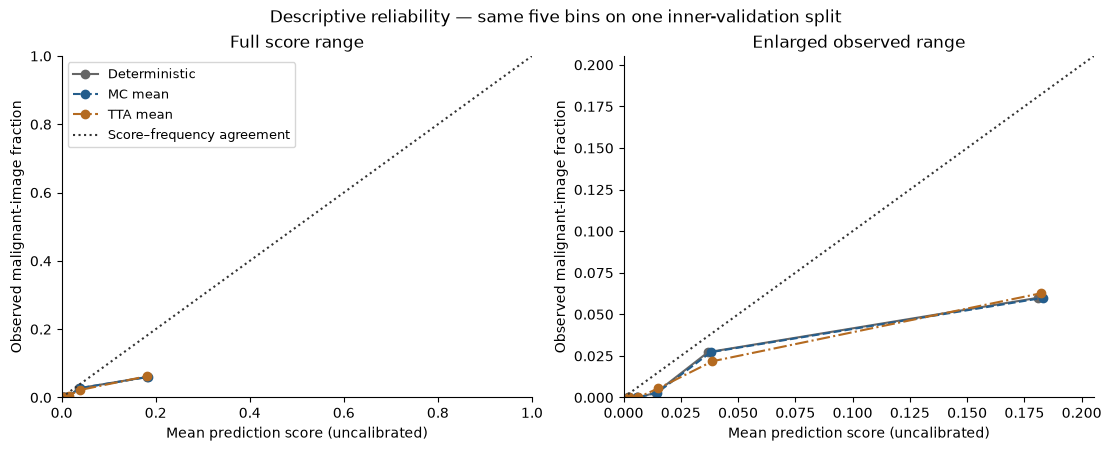

In [8]:
score_columns = {"Deterministic": "base_score", "MC mean": "mc_mean_score", "TTA mean": "tta_mean_score"}
quality_rows, reliability_parts = [], []
for name, column in score_columns.items():
    quality_rows.append({"prediction": name, **probability_metrics(summary.target, summary[column])})
    bins = calibration_bins(summary.target, summary[column], n_bins=5, groups=summary.patient_id)
    bins["prediction"] = name
    reliability_parts.append(bins)
fit_prevalence = float(context["fitting_frame"].target.mean())
quality_rows.append({"prediction": "Constant fitting prevalence",
    **probability_metrics(summary.target, np.full(len(summary), fit_prevalence))})
quality = pd.DataFrame(quality_rows)
reliability = pd.concat(reliability_parts, ignore_index=True)
quality.to_csv(OUTPUT_DIR / "prediction_quality.csv", index=False)
reliability.to_csv(OUTPUT_DIR / "descriptive_reliability.csv", index=False)
display(quality.round(5))
print("Validation malignant-image fraction:", round(float(summary.target.mean()), 5),
      "| fitting prevalence:", round(fit_prevalence, 5))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
zoom_max = max(0.05, float(max(reliability.mean_probability.max(), reliability.observed_rate.max())) * 1.12)
for ax, limit, title in zip(axes, [1.0, zoom_max], ["Full score range", "Enlarged observed range"]):
    for (name, bins), color, style in zip(reliability.groupby("prediction", sort=False),
        ["#666666", "#245D8C", "#B46A20"], ["-", "--", "-."]):
        ax.plot(bins.mean_probability, bins.observed_rate, marker="o", color=color, linestyle=style, label=name)
    ax.plot([0, limit], [0, limit], linestyle=":", color="#333333", label="Score–frequency agreement")
    ax.set(xlabel="Mean prediction score (uncalibrated)", ylabel="Observed malignant-image fraction",
           xlim=(0, limit), ylim=(0, limit), title=title)
axes[0].legend(fontsize=9)
fig.suptitle("Descriptive reliability — same five bins on one inner-validation split")
save_figure("descriptive_reliability.png", fig)


## 8. Examine the two variation measures

The distributions below count images by MC or TTA SD. Each panel has its own
score-SD scale because the procedures perturb different things. Wider variation
is not proof of malignancy or error, and a model can be confidently wrong.
The scatterplot shows whether the same images vary under both procedures.


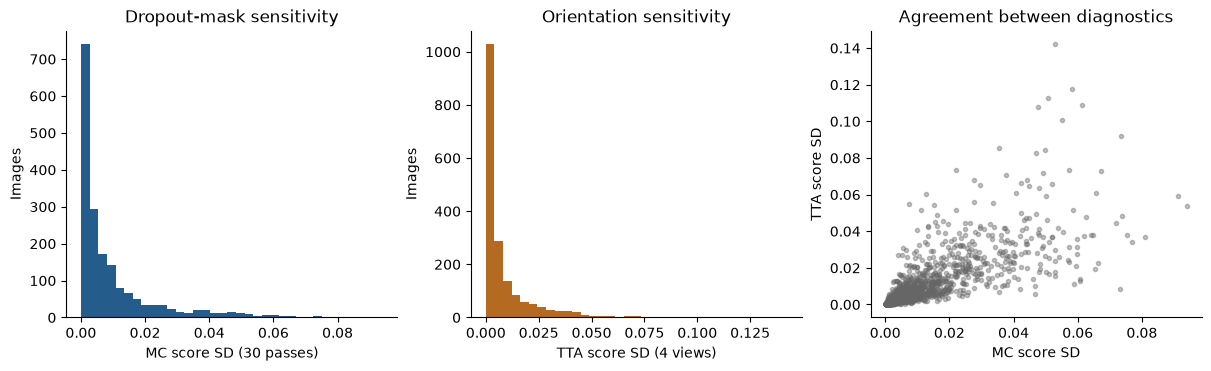

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
axes[0].hist(summary.mc_score_sd, bins=35, color="#245D8C")
axes[0].set(xlabel="MC score SD (30 passes)", ylabel="Images", title="Dropout-mask sensitivity")
axes[1].hist(summary.tta_score_sd, bins=35, color="#B46A20")
axes[1].set(xlabel="TTA score SD (4 views)", ylabel="Images", title="Orientation sensitivity")
axes[2].scatter(summary.mc_score_sd, summary.tta_score_sd, s=9, alpha=0.4, color="#666666")
axes[2].set(xlabel="MC score SD", ylabel="TTA score SD", title="Agreement between diagnostics")
save_figure("uncertainty_distributions.png", fig)


## 9. Test whether SD adds value beyond simple referral rankings

Across both methods, every ranking uses the **same deterministic predictions**,
labels and predeclared referral fractions. We rank descending SD, descending
ordinary prediction score, and descending predictive entropy
`−s log(s) − (1−s) log(1−s)`. Score ranking prioritises predicted malignant risk;
entropy prioritises scores near 0.5. Entropy is a function of an uncalibrated
score, not a validated measure of clinical risk. Keeping `base_score` fixed
isolates the value of the ranking from any change caused by MC/TTA averaging.

Repeated seeded random referrals provide a baseline (100 recorded seeds).
Referral removes a fixed number of images from automatic evaluation; it does
not simulate successful diagnosis by a reviewer. Fractions are fixed before
looking at labels, and ties use image ID. No operational fraction is selected.

Retained-set classification error uses the fixed descriptive score cutoff 0.5;
MAE and Brier expose score errors that this cutoff can hide with rare malignancy.
Malignant images referred and distinct patients with a malignant image referred
have separate denominators. The policy refers images, not whole patients.


In [10]:
referral = evaluate_referral(summary, fractions=REFERRAL_FRACTIONS,
    n_random=RANDOM_REPEATS, seed=REFERRAL_SEED)
referral.to_csv(OUTPUT_DIR / "referral_rankings.csv", index=False)
print("Retained error: fixed descriptive score cutoff 0.5; no threshold fitting")
display(referral[(referral.referral_fraction == 0.20) & (referral.ranking != "random")].round(5))


Retained error: fixed descriptive score cutoff 0.5; no threshold fitting


,method,ranking,random_seed,referral_fraction,score_column,fixed_score_cutoff,n_images,n_patients,n_malignant_images,n_malignant_patients,...,n_retained,n_patients_referred,n_patients_retained,retained_error,retained_brier,retained_score_mae,n_malignant_images_referred,malignant_referred_fraction,n_malignant_patients_referred,malignant_patients_referred_fraction
3,mc,uncertainty_sd,NaN,0.2,base_score,0.5,1834,113,33,18,...,1468,90,106,0.00545,0.00559,0.02017,25,0.75758,13,0.72222
10,mc,prediction_score,NaN,0.2,base_score,0.5,1834,113,33,18,...,1468,92,108,0.00749,0.00740,0.02169,22,0.66667,11,0.61111
17,mc,predictive_entropy,NaN,0.2,base_score,0.5,1834,113,33,18,...,1468,92,108,0.00749,0.00740,0.02169,22,0.66667,11,0.61111
724,tta,uncertainty_sd,NaN,0.2,base_score,0.5,1834,113,33,18,...,1468,90,107,0.00749,0.00719,0.02441,24,0.72727,12,0.66667
731,tta,prediction_score,NaN,0.2,base_score,0.5,1834,113,33,18,...,1468,92,108,0.00749,0.00740,0.02169,22,0.66667,11,0.61111
738,tta,predictive_entropy,NaN,0.2,base_score,0.5,1834,113,33,18,...,1468,92,108,0.00749,0.00740,0.02169,22,0.66667,11,0.61111


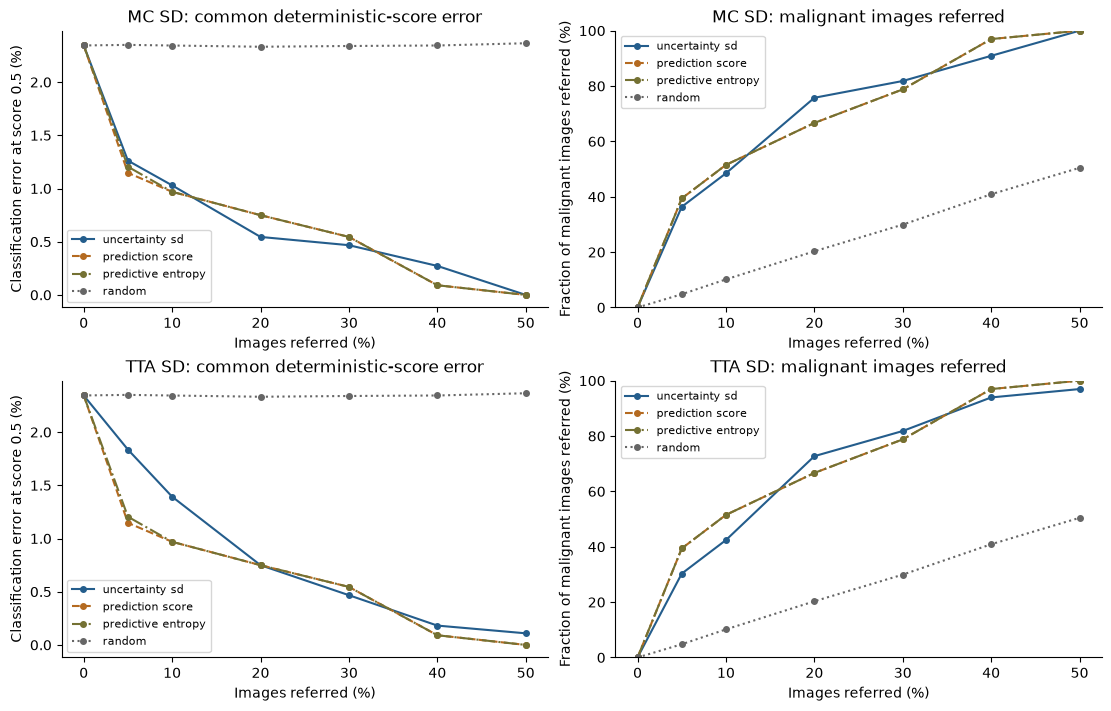

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for row, method in enumerate(["mc", "tta"]):
    data = referral[referral.method == method]
    for ranking in ["uncertainty_sd", "prediction_score", "predictive_entropy", "random"]:
        values = data[data.ranking == ranking].groupby("referral_fraction", as_index=False).mean(numeric_only=True)
        for col, metric in enumerate(["retained_error", "malignant_referred_fraction"]):
            axes[row, col].plot(values.referral_fraction * 100, values[metric] * 100,
                marker="o", markersize=4, color=COLORS[ranking], linestyle=LINESTYLES[ranking], label=ranking.replace("_", " "))
    axes[row, 0].set(title=f"{method.upper()} SD: common deterministic-score error", ylabel="Classification error at score 0.5 (%)")
    axes[row, 1].set(title=f"{method.upper()} SD: malignant images referred", ylabel="Fraction of malignant images referred (%)", ylim=(0, 100))
    for ax in axes[row]:
        ax.set_xlabel("Images referred (%)")
        ax.legend(fontsize=8)
save_figure("referral_comparisons.png", fig)


## 10. Quantify paired differences with patient bootstrap intervals

We resample 113 whole validation-patient groups with replacement 2,000 times,
keeping each patient's images together and recomputing referral rankings and
budgets in every replicate. Differences are SD ranking minus score, entropy or
the mean random ranking on the same resample. Negative retained-error
differences favour SD; positive malignant-referral differences favour SD.
Undefined malignant fractions in resamples without malignancies remain missing,
and valid replicate counts are reported.

The 95% percentile intervals are conditional on these already fitted predictions
and this finite set of MC masks/TTA views. They do not include training-seed
variation or remove optimism from selecting the checkpoint on these validation
patients. Testing several fractions adds multiplicity; a favourable point does
not establish a referral policy.


In [12]:
differences = referral_patient_bootstrap(summary, fractions=REFERRAL_FRACTIONS,
    n_bootstrap=PATIENT_BOOTSTRAPS, n_random=RANDOM_REPEATS, seed=BOOTSTRAP_SEED,
    referral_seed=REFERRAL_SEED)
differences.to_csv(OUTPUT_DIR / "paired_patient_bootstrap_differences.csv", index=False)
display(differences[differences.referral_fraction == 0.20].round(5))


,method,ranking,comparator,score_column,referral_fraction,metric,estimate,ci_lower,ci_upper,n_requested,n_valid,n_undefined,n_random_per_replicate,bootstrap_seed,referral_seed
6,mc,uncertainty_sd,prediction_score,base_score,0.2,retained_error,-0.00204,-0.00359,0.00000,2000,2000,0,100,20242,17042
7,mc,uncertainty_sd,prediction_score,base_score,0.2,malignant_referred_fraction,0.09091,0.00000,0.16667,2000,2000,0,100,20242,17042
20,mc,uncertainty_sd,predictive_entropy,base_score,0.2,retained_error,-0.00204,-0.00359,0.00000,2000,2000,0,100,20242,17042
21,mc,uncertainty_sd,predictive_entropy,base_score,0.2,malignant_referred_fraction,0.09091,0.00000,0.16667,2000,2000,0,100,20242,17042
34,mc,uncertainty_sd,random,base_score,0.2,retained_error,-0.01787,-0.02672,-0.00881,2000,2000,0,100,20242,17042
35,mc,uncertainty_sd,random,base_score,0.2,malignant_referred_fraction,0.55455,0.26717,0.69254,2000,2000,0,100,20242,17042
48,tta,uncertainty_sd,prediction_score,base_score,0.2,retained_error,0.00000,-0.00227,0.00527,2000,2000,0,100,20242,17042
49,tta,uncertainty_sd,prediction_score,base_score,0.2,malignant_referred_fraction,0.06061,-0.11765,0.16667,2000,2000,0,100,20242,17042
62,tta,uncertainty_sd,predictive_entropy,base_score,0.2,retained_error,0.00000,-0.00227,0.00527,2000,2000,0,100,20242,17042
63,tta,uncertainty_sd,predictive_entropy,base_score,0.2,malignant_referred_fraction,0.06061,-0.11765,0.16667,2000,2000,0,100,20242,17042


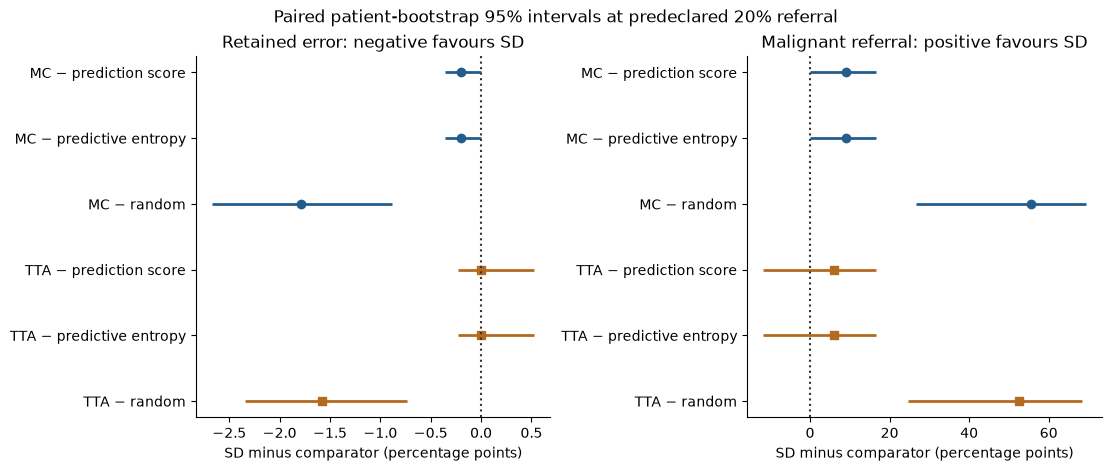

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)
for ax, metric, title in zip(axes, ["retained_error", "malignant_referred_fraction"],
    ["Retained error: negative favours SD", "Malignant referral: positive favours SD"]):
    values = differences[(differences.referral_fraction == 0.20) & (differences.metric == metric)].reset_index(drop=True)
    for index, row in enumerate(values.itertuples()):
        color = "#245D8C" if row.method == "mc" else "#B46A20"
        ax.hlines(index, row.ci_lower * 100, row.ci_upper * 100, color=color, linewidth=2)
        ax.plot(row.estimate * 100, index, marker="o" if row.method == "mc" else "s", color=color)
    ax.axvline(0, color="#333333", linestyle=":")
    ax.set_yticks(range(len(values)), [f"{r.method.upper()} − {r.comparator.replace('_', ' ')}" for r in values.itertuples()])
    ax.set(xlabel="SD minus comparator (percentage points)", title=title)
    ax.invert_yaxis()
fig.suptitle("Paired patient-bootstrap 95% intervals at predeclared 20% referral")
save_figure("paired_patient_bootstrap_differences.png", fig)


## 11. Preserve the training artifacts and record provenance

File hashes compare checkpoints, histories, old prototype outputs and the
historical notebook before and after inference. We also retain the checkpoint
and split identities, deterministic preprocessing profile, all pass seeds,
batch size, device and package versions, referral seeds/fractions, bootstrap
settings and the current inference source hashes. Raw, summary and figure
outputs belong only to this new run directory.


In [14]:
preservation = assert_preserved_artifacts(protected)
save_json("preservation_receipt.json", preservation)
source_paths = [PROJECT_ROOT / "src/melanoma_detection" / name for name in
    ["image_uncertainty.py", "image_uncertainty_evaluation.py", "image_model.py", "image_transforms.py"]]
save_json("analysis_provenance.json", {
    "source_run": SOURCE_RUN, "architecture": ARCHITECTURE, "recipe_id": RECIPE_ID,
    "condition_id": CONDITION_ID, "evaluation_split": "inner_validation",
    "evaluation_status": "exploratory_inner_validation_not_outer_oof",
    "mc_passes": MC_PASSES, "inference_seed": INFERENCE_SEED,
    "tta_views": tta_pass_ids, "referral_fractions": list(REFERRAL_FRACTIONS),
    "random_referral_seed": REFERRAL_SEED, "random_repeats": RANDOM_REPEATS,
    "bootstrap_seed": BOOTSTRAP_SEED, "patient_bootstrap_replicates": PATIENT_BOOTSTRAPS,
    "bootstrap_interval": "paired patient-cluster percentile 95%; conditional on fitted predictions",
    "classification_cutoff": 0.5, "calibration_fitted": False, "threshold_selected": False,
    "reserved_test_loaded": False, "outer_fold_predictions_generated": False,
    "source_sha256": {str(path.relative_to(PROJECT_ROOT)): file_sha256(path) for path in source_paths},
    "output_sha256": {path.name: file_sha256(path) for path in OUTPUT_DIR.glob("*.csv")},
})
display(pd.DataFrame([preservation]))
print("Saved all diagnostic outputs to", OUTPUT_DIR)


,protected_files_checked,all_protected_files_unchanged
0,124,True


Saved all diagnostic outputs to C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\results\image_uncertainty_runs\efficientnet_b0_lr3e5_sqrt_mc30_tta4_20261003T235530258956Z


## Limitations

This is one small, imbalanced inner-validation split reused for epoch and pilot
recipe selection. Patient separation prevents direct training leakage but does
not make these diagnostics an unbiased final evaluation. Neither a favourable
architecture AP nor a favourable referral fraction selects the final model.

Dropout SD covers explicit dropout-mask variation only. It excludes backbone
stochastic depth, training-seed variation and distribution shift. TTA covers four
conservative orientations only; it does not estimate total uncertainty. Thirty
passes are a finite reference, and rank convergence can be slower than score
convergence. Low uncertainty can accompany consistent errors.

The class-weighted scores are uncalibrated. Reliability bins have sparse
malignant support, and image-level referral does not establish patient-level
clinical benefit. The fixed cutoff 0.5 is descriptive. Bootstrap intervals are
conditional and do not correct selection optimism or multiple comparisons.
No calibrator, referral threshold, fusion model, outer OOF evaluation or reserved
test evaluation is implemented here.

## Summary

The current workflow attaches uncertainty to an explicitly selected recorded
best checkpoint, reproduces its exact preparation and patient membership, and
checks inference without changing training artifacts. Raw scores, MC means/SDs
and TTA means/SDs are kept separate and saved with provenance. The executed
summary below reports the observed prediction metrics; the referral tables and
paired intervals determine whether SD adds useful information on this split.
All findings remain exploratory until confirmed within a frozen patient-safe
evaluation procedure on independent outer patients.


In [15]:
observed = quality.set_index("prediction")
display(Markdown(f"**Executed checkpoint:** {ARCHITECTURE}, run `{SOURCE_RUN}`, recipe `{RECIPE_ID}`, "
    f"best epoch {context['checkpoint']['epoch']}. **Population:** {len(summary):,} inner-validation images "
    f"from {summary.patient_id.nunique()} patients, including {int(summary.target.sum())} malignant images. "
    f"**AP:** deterministic {observed.loc['Deterministic', 'average_precision']:.4f}, "
    f"MC mean {observed.loc['MC mean', 'average_precision']:.4f}, "
    f"TTA mean {observed.loc['TTA mean', 'average_precision']:.4f}. "
    "Averaging performance does not establish that uncertainty improves referral; inspect the matched rankings and paired intervals."))
at_twenty = referral[(referral.referral_fraction == 0.20) & (referral.ranking != "random")]
for method in ["mc", "tta"]:
    rows = at_twenty[at_twenty.method == method].set_index("ranking")
    pair = differences[(differences.method == method) & (differences.referral_fraction == 0.20)
        & (differences.comparator == "prediction_score")].set_index("metric")
    malignant_pair = pair.loc["malignant_referred_fraction"]
    error_pair = pair.loc["retained_error"]
    display(Markdown(f"**{method.upper()} at the predeclared 20% referral:** SD referred "
        f"{int(rows.loc['uncertainty_sd', 'n_malignant_images_referred'])} malignant images versus "
        f"{int(rows.loc['prediction_score', 'n_malignant_images_referred'])} by ordinary score ranking. "
        f"The paired malignant-referral difference is {100 * malignant_pair['estimate']:.2f} percentage points "
        f"(95% patient-bootstrap interval {100 * malignant_pair['ci_lower']:.2f} to {100 * malignant_pair['ci_upper']:.2f}). "
        f"The retained-error difference is {100 * error_pair['estimate']:.3f} percentage points "
        f"(interval {100 * error_pair['ci_lower']:.3f} to {100 * error_pair['ci_upper']:.3f})."))
ordinary_pairs = differences[(differences.referral_fraction == 0.20) & (differences.comparator == "prediction_score")]
zero_count = int(((ordinary_pairs.ci_lower <= 0) & (ordinary_pairs.ci_upper >= 0)).sum())
display(Markdown(f"**Decision:** keep SD as an exploratory diagnostic. {zero_count} of {len(ordinary_pairs)} "
    "displayed intervals against ordinary score ranking include zero. The checkpoint was selected using these "
    "validation patients; this run does not establish independent evidence of improvement or justify a referral "
    "threshold. No architecture is declared final."))


**Executed checkpoint:** efficientnet_b0, run `b0_augmentation_12e_v1`, recipe `lr3e5_sqrt`, best epoch 6. **Population:** 1,834 inner-validation images from 113 patients, including 33 malignant images. **AP:** deterministic 0.1383, MC mean 0.1375, TTA mean 0.1413. Averaging performance does not establish that uncertainty improves referral; inspect the matched rankings and paired intervals.

**MC at the predeclared 20% referral:** SD referred 25 malignant images versus 22 by ordinary score ranking. The paired malignant-referral difference is 9.09 percentage points (95% patient-bootstrap interval 0.00 to 16.67). The retained-error difference is -0.204 percentage points (interval -0.359 to 0.000).

**TTA at the predeclared 20% referral:** SD referred 24 malignant images versus 22 by ordinary score ranking. The paired malignant-referral difference is 6.06 percentage points (95% patient-bootstrap interval -11.76 to 16.67). The retained-error difference is 0.000 percentage points (interval -0.227 to 0.527).

**Decision:** keep SD as an exploratory diagnostic. 4 of 4 displayed intervals against ordinary score ranking include zero. The checkpoint was selected using these validation patients; this run does not establish independent evidence of improvement or justify a referral threshold. No architecture is declared final.